# Atividade de Machine Learning — Google Colab

Aluno: Jordana de Oliveira Farias Ferreira

Curso: Análise e Desenvolvimento de Sistemas

Este notebook resolve os 20 exercícios da atividade usando Python, NumPy, Pandas, Matplotlib, SciPy e Scikit-Learn.
Todos os conjuntos de dados são gerados ou carregados do próprio Scikit-Learn, então basta executar Ambiente de execução → Executar tudo.

In [4]:
# Configuração geral
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (make_classification, make_moons, make_blobs,
                              make_circles, load_iris, load_breast_cancer, load_wine)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import accuracy_score, silhouette_score, adjusted_rand_score
from sklearn.exceptions import ConvergenceWarning
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore", category=ConvergenceWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (8, 5)
print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## Exercício 1: Inspeção de Parâmetros da Regressão Logística (Paramétrico)
**Objetivo:** verificar a contagem fixa de parâmetros em um modelo paramétrico.

A Regressão Logística aprende um peso por atributo (`coef_`) mais um viés (`intercept_`).
O número de parâmetros depende apenas do número de atributos, não da quantidade de amostras de treino.

In [5]:
n_features = 10
print(f"{'Amostras':>10} | {'coef_':>8} | {'intercept_':>10} | {'Total params':>12}")
print("-" * 50)
for n_samples in [100, 1_000, 10_000, 100_000]:
    X, y = make_classification(n_samples=n_samples, n_features=n_features, random_state=RANDOM_STATE)
    lr = LogisticRegression(max_iter=1000).fit(X, y)
    total = lr.coef_.size + lr.intercept_.size
    print(f"{n_samples:>10} | {lr.coef_.size:>8} | {lr.intercept_.size:>10} | {total:>12}")

print("\nConclusão: o número de parâmetros é sempre n_features + 1 = 11, independente do tamanho do treino.")

  Amostras |    coef_ | intercept_ | Total params
--------------------------------------------------
       100 |       10 |          1 |           11
      1000 |       10 |          1 |           11
     10000 |       10 |          1 |           11
    100000 |       10 |          1 |           11

Conclusão: o número de parâmetros é sempre n_features + 1 = 11, independente do tamanho do treino.


## Exercício 2: A Memória do KNN (Não Paramétrico)
Objetivo: demonstrar que o KNN armazena o conjunto de treino inteiro.

O KNN não "aprende" pesos: no `fit` ele apenas guarda os dados. Quanto mais amostras, mais memória o modelo ocupa.

In [6]:
import pickle

print(f"{'Amostras':>10} | {'Amostras guardadas':>18} | {'Tamanho KNN (KB)':>16} | {'Tamanho LogReg (KB)':>19}")
print("-" * 75)
for n_samples in [100, 1_000, 10_000, 100_000]:
    X, y = make_classification(n_samples=n_samples, n_features=10, random_state=RANDOM_STATE)
    knn = KNeighborsClassifier(n_neighbors=5).fit(X, y)
    lr = LogisticRegression(max_iter=1000).fit(X, y)
    kb_knn = len(pickle.dumps(knn)) / 1024
    kb_lr = len(pickle.dumps(lr)) / 1024
    print(f"{n_samples:>10} | {knn.n_samples_fit_:>18} | {kb_knn:>16.1f} | {kb_lr:>19.1f}")

# Prova: os dados guardados internamente são idênticos aos de treino
print("\nDados internos == X de treino?", np.array_equal(knn._fit_X, X))
print("Conclusão: o KNN cresce linearmente com o treino; a Regressão Logística permanece com tamanho constante.")

  Amostras | Amostras guardadas | Tamanho KNN (KB) | Tamanho LogReg (KB)
---------------------------------------------------------------------------
       100 |                100 |             11.1 |                 0.8
      1000 |               1000 |            106.7 |                 0.8
     10000 |              10000 |           1034.5 |                 0.8
    100000 |             100000 |          10144.0 |                 0.8

Dados internos == X de treino? True
Conclusão: o KNN cresce linearmente com o treino; a Regressão Logística permanece com tamanho constante.


## Exercício 3: Comparação de Tempo de Inferência (Paramétrico vs. Não Paramétrico)
Objetivo: medir a velocidade de predição em um lote grande de dados.

A Regressão Logística prevê com uma multiplicação de matriz. O KNN precisa calcular distâncias para todos os pontos de treino.

Regressão Logística    -> predição de 50,000 amostras em 0.0043s | acurácia 0.890
KNN (k=5)              -> predição de 50,000 amostras em 2.8915s | acurácia 0.875

O KNN foi 668x mais lento na inferência.


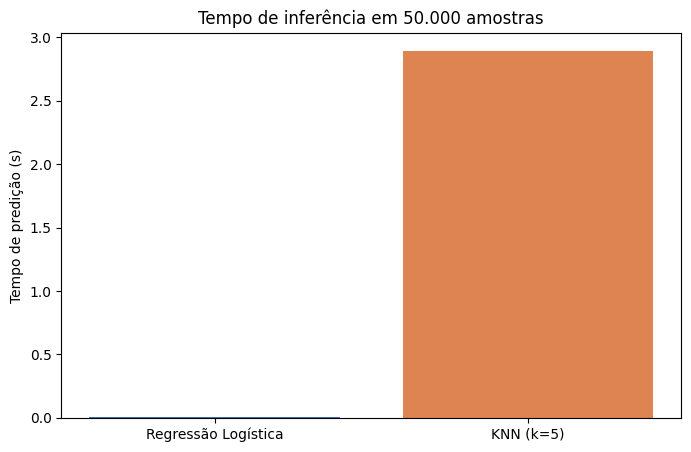

In [7]:
X, y = make_classification(n_samples=60_000, n_features=20, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=50_000, random_state=RANDOM_STATE)

modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}
tempos = {}
for nome, m in modelos.items():
    m.fit(X_train, y_train)
    t0 = time.perf_counter()
    pred = m.predict(X_test)
    tempos[nome] = time.perf_counter() - t0
    print(f"{nome:<22} -> predição de {len(X_test):,} amostras em {tempos[nome]:.4f}s | acurácia {accuracy_score(y_test, pred):.3f}")

print(f"\nO KNN foi {tempos['KNN (k=5)'] / tempos['Regressão Logística']:.0f}x mais lento na inferência.")

plt.bar(tempos.keys(), tempos.values(), color=["#4C72B0", "#DD8452"])
plt.ylabel("Tempo de predição (s)")
plt.title("Tempo de inferência em 50.000 amostras")
plt.show()

## Exercício 4: Fronteiras de Decisão (Reta vs. Curva Adaptativa)
Objetivo: visualizar como o modelo não paramétrico se molda melhor a dados não lineares.

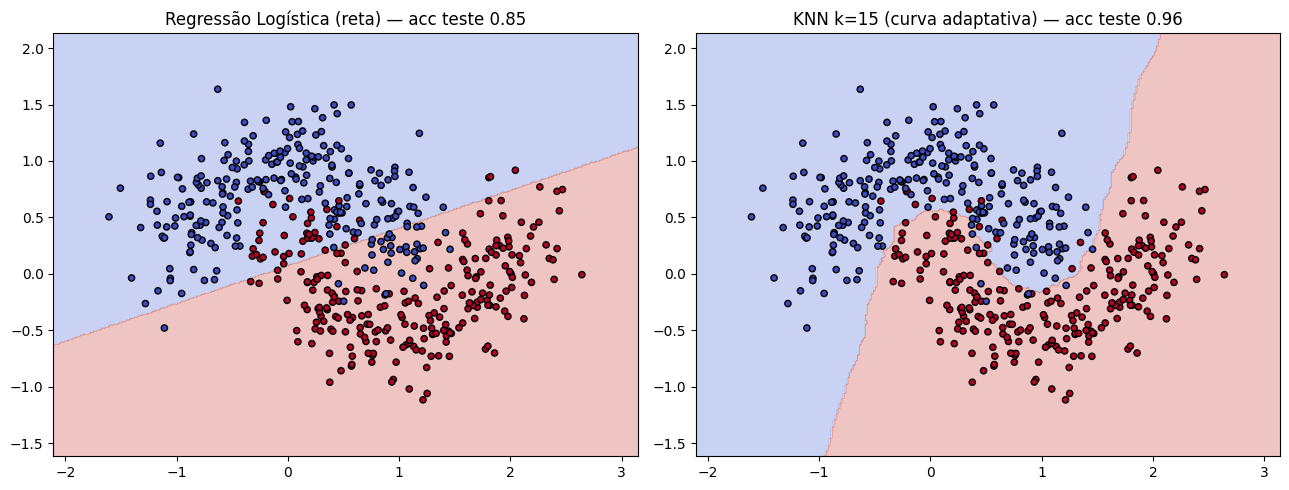

In [8]:
def plot_fronteira(modelo, X, y, ax, titulo):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_title(titulo)

X, y = make_moons(n_samples=500, noise=0.25, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

lr = LogisticRegression().fit(X_train, y_train)
knn = KNeighborsClassifier(n_neighbors=15).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_fronteira(lr, X, y, axes[0], f"Regressão Logística (reta) — acc teste {lr.score(X_test, y_test):.2f}")
plot_fronteira(knn, X, y, axes[1], f"KNN k=15 (curva adaptativa) — acc teste {knn.score(X_test, y_test):.2f}")
plt.tight_layout(); plt.show()

## Exercício 5: K-Means com e sem Escalonamento (StandardScaler)
Objetivo: mostrar o impacto brutal da escala no K-Means.

Usamos o dataset Wine (178 vinhos, 13 atributos químicos). Os atributos têm escalas muito diferentes: `proline` vai até ~1.700, enquanto `hue` fica perto de 1. Sem escalonar, a distância euclidiana é dominada pelo `proline`.

Amplitude (máx - mín) de alguns atributos:
proline                         1402.00
magnesium                         92.00
alcalinity_of_ash                 19.40
color_intensity                   11.72
malic_acid                         5.06
flavanoids                         4.74
alcohol                            3.80
proanthocyanins                    3.17
total_phenols                      2.90
od280/od315_of_diluted_wines       2.73
ash                                1.87
hue                                1.23
nonflavanoid_phenols               0.53 



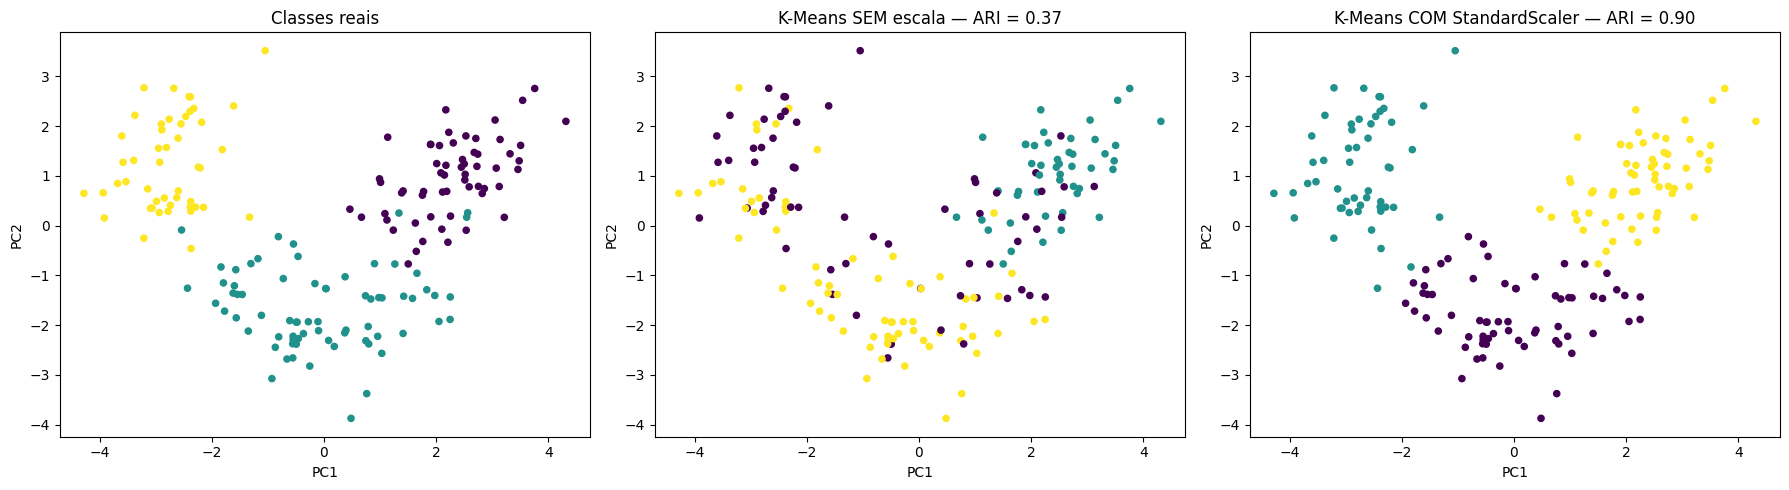

Adjusted Rand Index (1 = agrupamento perfeito): sem escala = 0.37 | com escala = 0.90
Sem escala o K-Means praticamente só enxerga o 'proline'; com escala todos os atributos contribuem igualmente.


In [9]:
from sklearn.decomposition import PCA

wine = load_wine()
X_wine, y_wine = wine.data, wine.target

print("Amplitude (máx - mín) de alguns atributos:")
amp = pd.Series(X_wine.max(0) - X_wine.min(0), index=wine.feature_names).sort_values(ascending=False)
print(amp.round(2).to_string(), "\n")

km_sem = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_wine)
X_wine_esc = StandardScaler().fit_transform(X_wine)
km_com = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_wine_esc)

ari_sem = adjusted_rand_score(y_wine, km_sem.labels_)
ari_com = adjusted_rand_score(y_wine, km_com.labels_)

# PCA em 2D apenas para visualizar os grupos
X_2d = PCA(n_components=2).fit_transform(X_wine_esc)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=y_wine, cmap="viridis", s=20); axes[0].set_title("Classes reais")
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=km_sem.labels_, cmap="viridis", s=20); axes[1].set_title(f"K-Means SEM escala — ARI = {ari_sem:.2f}")
axes[2].scatter(X_2d[:, 0], X_2d[:, 1], c=km_com.labels_, cmap="viridis", s=20); axes[2].set_title(f"K-Means COM StandardScaler — ARI = {ari_com:.2f}")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

print(f"Adjusted Rand Index (1 = agrupamento perfeito): sem escala = {ari_sem:.2f} | com escala = {ari_com:.2f}")
print("Sem escala o K-Means praticamente só enxerga o 'proline'; com escala todos os atributos contribuem igualmente.")

## Exercício 6: Método do Cotovelo (Elbow Method)
Objetivo: encontrar visualmente o número ideal de grupos ($K$).

Plotamos a inércia (soma das distâncias quadradas aos centróides) para vários $K$. O "cotovelo" indica o ponto onde aumentar $K$ deixa de trazer ganho relevante.

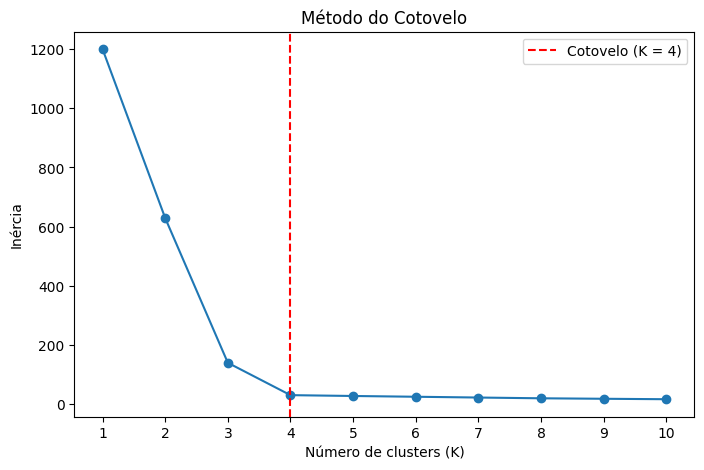

K= 1  inércia= 1200.00
K= 2  inércia=  628.53
K= 3  inércia=  138.77
K= 4  inércia=   29.28
K= 5  inércia=   26.45
K= 6  inércia=   23.85
K= 7  inércia=   21.22
K= 8  inércia=   18.63
K= 9  inércia=   17.02
K=10  inércia=   15.50


In [10]:
X_blobs, y_blobs = make_blobs(n_samples=600, centers=4, cluster_std=0.9, random_state=RANDOM_STATE)
X_blobs = StandardScaler().fit_transform(X_blobs)

ks = range(1, 11)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_blobs).inertia_ for k in ks]

plt.plot(ks, inercias, "o-")
plt.axvline(4, color="red", linestyle="--", label="Cotovelo (K = 4)")
plt.xlabel("Número de clusters (K)"); plt.ylabel("Inércia")
plt.title("Método do Cotovelo"); plt.xticks(ks); plt.legend(); plt.show()

for k, i in zip(ks, inercias):
    print(f"K={k:2d}  inércia={i:8.2f}")

## Exercício 7: Coeficiente de Silhueta para Validação de $K$
Objetivo: calcular o `silhouette_score` para validar agrupamentos.

A silhueta varia de -1 a 1: quanto maior, mais coesos e separados estão os grupos.

K= 2  silhouette=0.5634
K= 3  silhouette=0.7527
K= 4  silhouette=0.8157
K= 5  silhouette=0.6931
K= 6  silhouette=0.5726
K= 7  silhouette=0.4367
K= 8  silhouette=0.3293
K= 9  silhouette=0.3335
K=10  silhouette=0.3450

Melhor K pela silhueta: 4 (confirma o cotovelo do Exercício 6)


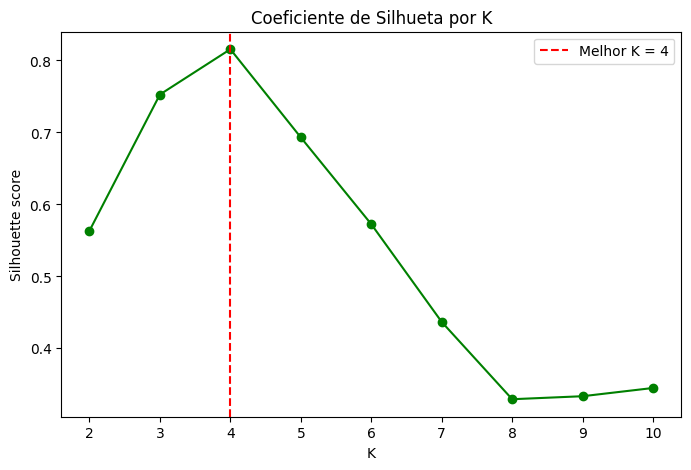

In [11]:
silhuetas = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_blobs)
    silhuetas[k] = silhouette_score(X_blobs, labels)
    print(f"K={k:2d}  silhouette={silhuetas[k]:.4f}")

melhor_k = max(silhuetas, key=silhuetas.get)
print(f"\nMelhor K pela silhueta: {melhor_k} (confirma o cotovelo do Exercício 6)")

plt.plot(list(silhuetas.keys()), list(silhuetas.values()), "o-", color="green")
plt.axvline(melhor_k, color="red", linestyle="--", label=f"Melhor K = {melhor_k}")
plt.xlabel("K"); plt.ylabel("Silhouette score"); plt.title("Coeficiente de Silhueta por K")
plt.legend(); plt.show()

## Exercício 8: DBSCAN para Identificação de Outliers/Ruídos
Objetivo: marcar automaticamente amostras atípicas (rótulo `-1`).

Clusters encontrados: 3
Pontos marcados como ruído (-1): 20


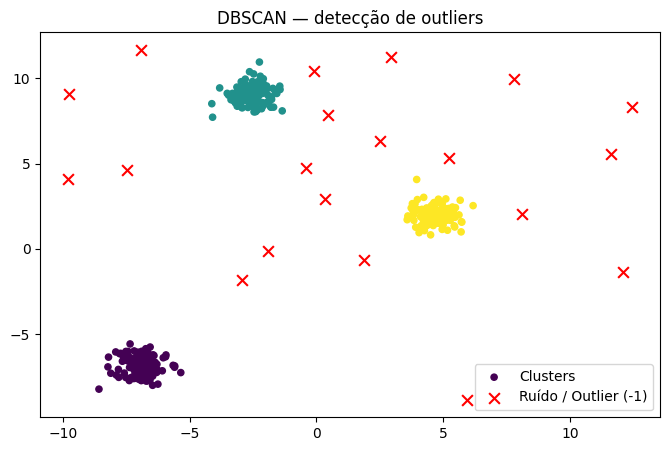

In [12]:
X_db, _ = make_blobs(n_samples=400, centers=3, cluster_std=0.5, random_state=RANDOM_STATE)
outliers = np.random.RandomState(0).uniform(low=X_db.min() - 2, high=X_db.max() + 2, size=(25, 2))
X_db = np.vstack([X_db, outliers])
X_db_esc = StandardScaler().fit_transform(X_db)

dbscan = DBSCAN(eps=0.25, min_samples=5).fit(X_db_esc)
labels = dbscan.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_ruido = int(np.sum(labels == -1))
print(f"Clusters encontrados: {n_clusters}")
print(f"Pontos marcados como ruído (-1): {n_ruido}")

mask = labels == -1
plt.scatter(X_db[~mask, 0], X_db[~mask, 1], c=labels[~mask], cmap="viridis", s=20, label="Clusters")
plt.scatter(X_db[mask, 0], X_db[mask, 1], c="red", marker="x", s=60, label="Ruído / Outlier (-1)")
plt.title("DBSCAN — detecção de outliers"); plt.legend(); plt.show()

## Exercício 9: Agrupamento Hierárquico e Plotagem de Dendrograma
Objetivo: construir e cortar a árvore hierárquica.

Usamos o dataset Iris (150 flores, 4 atributos) com ligação de **Ward**.

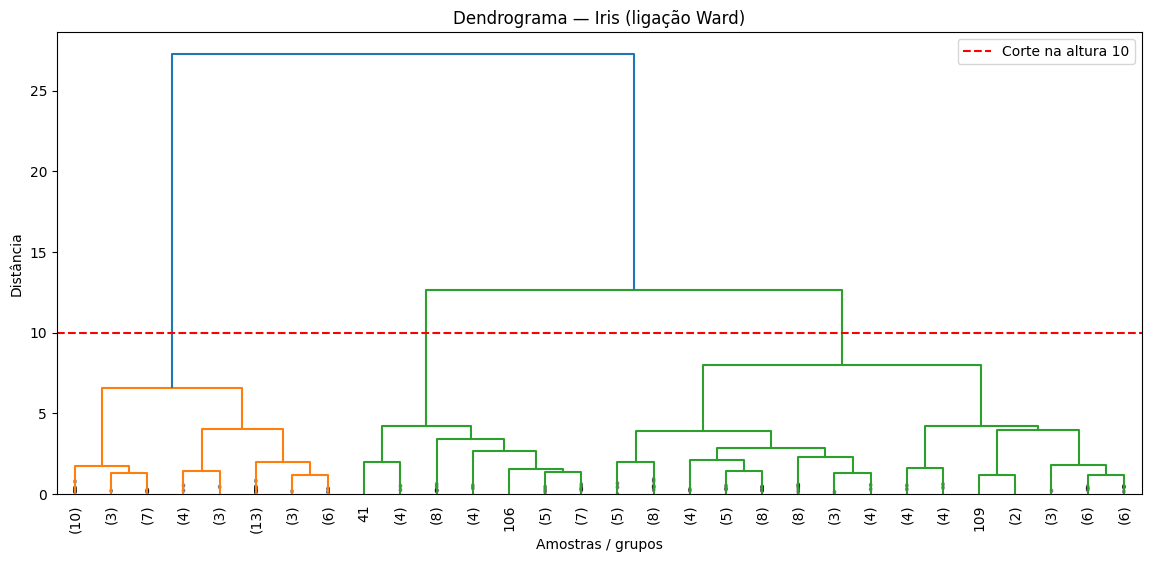

Grupos obtidos cortando na altura 10 -> 3
ARI (AgglomerativeClustering x espécies reais): 0.615
Cluster      0   1   2
Espécie               
setosa       0  49   1
versicolor  23   0  27
virginica   48   0   2


In [13]:
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

Z = linkage(X_iris, method="ward")
altura_corte = 10

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
plt.axhline(altura_corte, color="red", linestyle="--", label=f"Corte na altura {altura_corte}")
plt.title("Dendrograma — Iris (ligação Ward)"); plt.xlabel("Amostras / grupos"); plt.ylabel("Distância")
plt.legend(); plt.show()

# Cortando a árvore
grupos_corte = fcluster(Z, t=altura_corte, criterion="distance")
print("Grupos obtidos cortando na altura", altura_corte, "->", len(np.unique(grupos_corte)))

# Mesmo resultado com o Scikit-Learn
agg = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_iris)
print("ARI (AgglomerativeClustering x espécies reais):", round(adjusted_rand_score(iris.target, agg.labels_), 3))
print(pd.crosstab(iris.target_names[iris.target], agg.labels_, rownames=["Espécie"], colnames=["Cluster"]))

## Exercício 10: Comparativo K-Means vs. DBSCAN em Anéis Concêntricos
Objetivo: demonstrar a falha do K-Means em dados não esféricos.

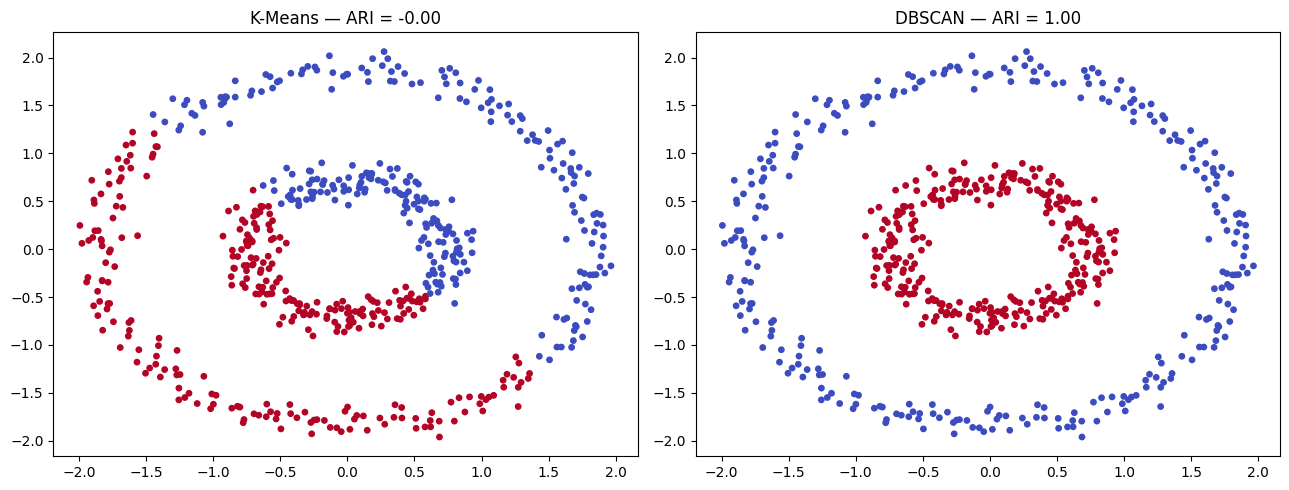

O K-Means divide o plano por uma reta (grupos esféricos ao redor de centróides) e falha.
O DBSCAN agrupa por densidade e separa corretamente os dois anéis.


In [14]:
X_c, y_c = make_circles(n_samples=600, factor=0.4, noise=0.05, random_state=RANDOM_STATE)
X_c = StandardScaler().fit_transform(X_c)

km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_c)
db = DBSCAN(eps=0.3, min_samples=5).fit(X_c)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_c[:, 0], X_c[:, 1], c=km.labels_, cmap="coolwarm", s=15)
axes[0].set_title(f"K-Means — ARI = {adjusted_rand_score(y_c, km.labels_):.2f}")
axes[1].scatter(X_c[:, 0], X_c[:, 1], c=db.labels_, cmap="coolwarm", s=15)
axes[1].set_title(f"DBSCAN — ARI = {adjusted_rand_score(y_c, db.labels_):.2f}")
plt.tight_layout(); plt.show()

print("O K-Means divide o plano por uma reta (grupos esféricos ao redor de centróides) e falha.")
print("O DBSCAN agrupa por densidade e separa corretamente os dois anéis.")

## Exercício 11: Cálculo Manual vs. Scikit-Learn de Gini e Entropia
Objetivo: entender a matemática por trás dos critérios de impureza.

$$Gini = 1 - \sum_{i} p_i^2 \qquad\qquad Entropia = -\sum_{i} p_i \log_2 p_i$$

Calculamos manualmente a impureza do nó raiz e comparamos com o valor que o Scikit-Learn armazena em `tree_.impurity`.

In [15]:
def gini(y):
    _, contagens = np.unique(y, return_counts=True)
    p = contagens / contagens.sum()
    return 1 - np.sum(p ** 2)

def entropia(y):
    _, contagens = np.unique(y, return_counts=True)
    p = contagens / contagens.sum()
    return -np.sum(p * np.log2(p))

# Exemplo didático simples
y_ex = np.array([0]*6 + [1]*4)
print("Exemplo com 6 da classe 0 e 4 da classe 1:")
print(f"  Gini     = 1 - (0.6² + 0.4²) = {gini(y_ex):.4f}")
print(f"  Entropia = -(0.6·log2 0.6 + 0.4·log2 0.4) = {entropia(y_ex):.4f}\n")

# Comparação com o Scikit-Learn no dataset Iris
X_iris_raw, y_iris = load_iris(return_X_y=True)
arv_gini = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE).fit(X_iris_raw, y_iris)
arv_ent = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE).fit(X_iris_raw, y_iris)

tabela = pd.DataFrame({
    "Critério": ["Gini", "Entropia"],
    "Manual (nó raiz)": [gini(y_iris), entropia(y_iris)],
    "Scikit-Learn (tree_.impurity[0])": [arv_gini.tree_.impurity[0], arv_ent.tree_.impurity[0]],
})
tabela["Iguais?"] = np.isclose(tabela.iloc[:, 1], tabela.iloc[:, 2])
display(tabela)

# Ganho de informação do primeiro split (manual)
t = arv_gini.tree_
esq, dir_ = t.children_left[0], t.children_right[0]
n, n_e, n_d = t.n_node_samples[0], t.n_node_samples[esq], t.n_node_samples[dir_]
ganho = t.impurity[0] - (n_e/n * t.impurity[esq] + n_d/n * t.impurity[dir_])
print(f"Redução de Gini no 1º split ({load_iris().feature_names[t.feature[0]]} <= {t.threshold[0]:.2f}): {ganho:.4f}")

Exemplo com 6 da classe 0 e 4 da classe 1:
  Gini     = 1 - (0.6² + 0.4²) = 0.4800
  Entropia = -(0.6·log2 0.6 + 0.4·log2 0.4) = 0.9710



,Critério,Manual (nó raiz),Scikit-Learn (tree_.impurity[0]),Iguais?
0,Gini,0.666667,0.666667,True
1,Entropia,1.584963,1.584963,True


Redução de Gini no 1º split (petal length (cm) <= 2.45): 0.3333


## Exercício 12: Visualização da Árvore com `plot_tree`
Objetivo: exportar o fluxograma da árvore de decisão.

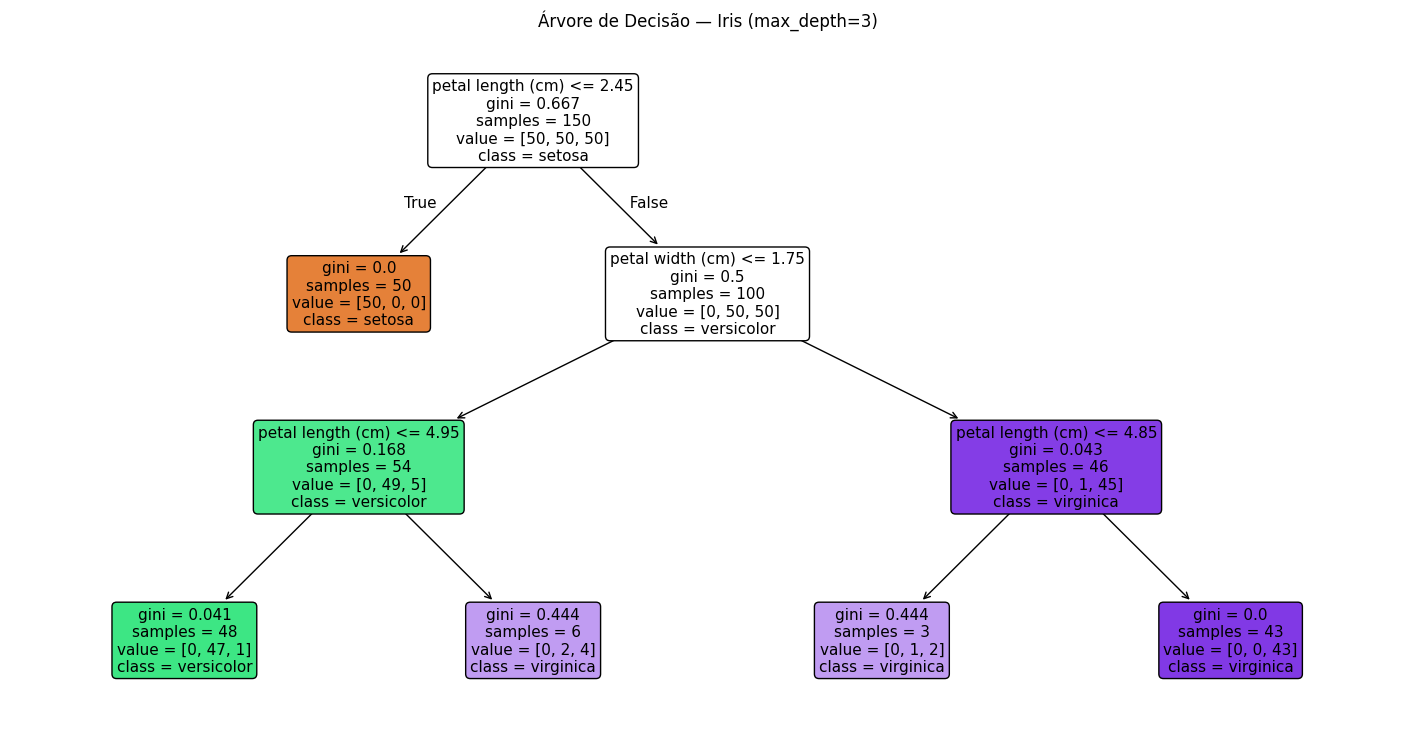

Fluxograma exportado para 'arvore_decisao.png' (veja no painel de arquivos do Colab).
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



In [16]:
arv = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_iris_raw, y_iris)

fig = plt.figure(figsize=(18, 9))
plot_tree(arv, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=11)
plt.title("Árvore de Decisão — Iris (max_depth=3)")
fig.savefig("arvore_decisao.png", dpi=150, bbox_inches="tight")
plt.show()
print("Fluxograma exportado para 'arvore_decisao.png' (veja no painel de arquivos do Colab).")

from sklearn.tree import export_text
print(export_text(arv, feature_names=iris.feature_names))

## Exercício 13: Diagnóstico de Overfitting via `max_depth` (Pré-poda)
Objetivo: plotar a curva de aprendizado de treino × teste.

Usamos o dataset Breast Cancer. Conforme a profundidade cresce, a acurácia de treino chega a 100%, mas a de teste estabiliza ou cai — sinal de overfitting.

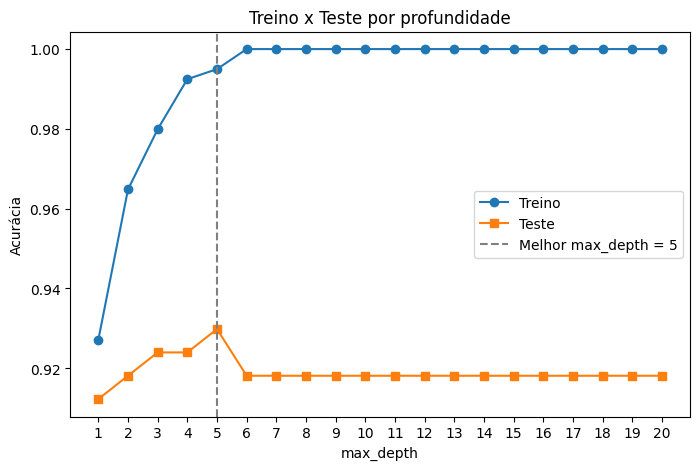

Melhor profundidade: 5 | acc teste = 0.930
Árvore sem limite: acc treino = 1.000 | acc teste = 0.918  -> overfitting


In [17]:
X_bc, y_bc = load_breast_cancer(return_X_y=True)
Xtr_bc, Xte_bc, ytr_bc, yte_bc = train_test_split(X_bc, y_bc, test_size=0.3, random_state=RANDOM_STATE, stratify=y_bc)

profundidades = range(1, 21)
acc_treino, acc_teste = [], []
for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xtr_bc, ytr_bc)
    acc_treino.append(m.score(Xtr_bc, ytr_bc))
    acc_teste.append(m.score(Xte_bc, yte_bc))

melhor_d = list(profundidades)[int(np.argmax(acc_teste))]
plt.plot(profundidades, acc_treino, "o-", label="Treino")
plt.plot(profundidades, acc_teste, "s-", label="Teste")
plt.axvline(melhor_d, color="gray", linestyle="--", label=f"Melhor max_depth = {melhor_d}")
plt.xlabel("max_depth"); plt.ylabel("Acurácia"); plt.title("Treino x Teste por profundidade")
plt.xticks(profundidades); plt.legend(); plt.show()

print(f"Melhor profundidade: {melhor_d} | acc teste = {max(acc_teste):.3f}")
print(f"Árvore sem limite: acc treino = {acc_treino[-1]:.3f} | acc teste = {acc_teste[-1]:.3f}  -> overfitting")

## Exercício 14: Extração de Importância dos Atributos (`feature_importances_`)
Objetivo: descobrir quais variáveis a árvore mais utilizou.

Top 10 atributos mais importantes:


,Importância
worst radius,0.726969
worst concave points,0.131403
worst texture,0.050081
texture error,0.030689
worst concavity,0.018988
mean fractal dimension,0.010400
worst area,0.009410
worst compactness,0.008835
worst fractal dimension,0.007319
smoothness error,0.003346


Atributos com importância zero (não usados pela árvore): 19 de 30


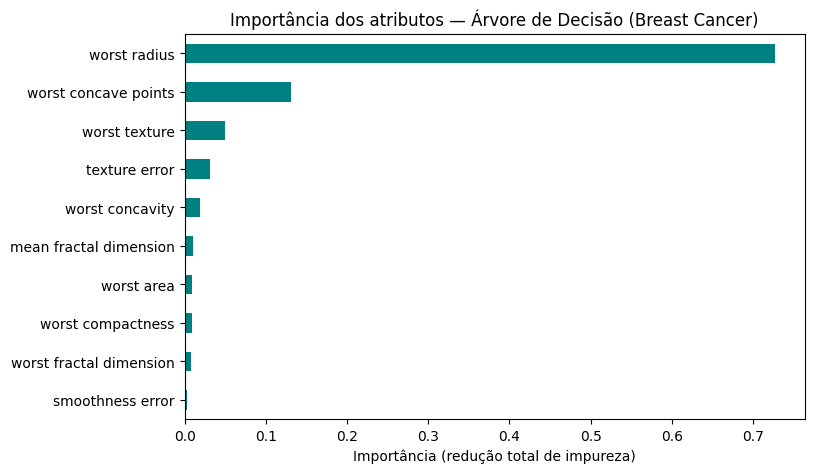

In [18]:
bc = load_breast_cancer()
arv_bc = DecisionTreeClassifier(max_depth=melhor_d, random_state=RANDOM_STATE).fit(Xtr_bc, ytr_bc)

importancias = pd.Series(arv_bc.feature_importances_, index=bc.feature_names).sort_values(ascending=False)
print("Top 10 atributos mais importantes:")
display(importancias.head(10).to_frame("Importância"))
print(f"Atributos com importância zero (não usados pela árvore): {(importancias == 0).sum()} de {len(importancias)}")

importancias.head(10).sort_values().plot(kind="barh", color="teal")
plt.title("Importância dos atributos — Árvore de Decisão (Breast Cancer)")
plt.xlabel("Importância (redução total de impureza)"); plt.show()

## Exercício 15: Pós-Poda com Cost Complexity Pruning (`ccp_alpha`)
Objetivo: aplicar pós-poda usando o hiperparâmetro `ccp_alpha`.

Primeiro a árvore cresce totalmente; depois `cost_complexity_pruning_path` gera os valores de alfa que vão podando os ramos menos úteis.

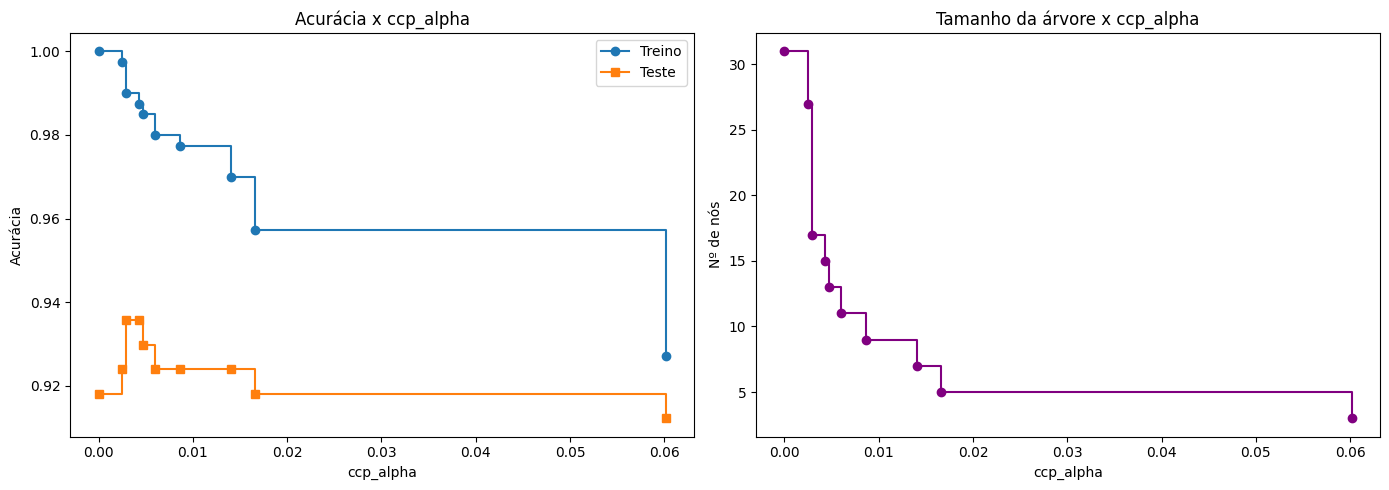

Árvore sem poda :  31 nós | acc teste = 0.918
Melhor ccp_alpha = 0.00295:  17 nós | acc teste = 0.936


In [19]:
caminho = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(Xtr_bc, ytr_bc)
alphas = caminho.ccp_alphas[:-1]  # o último alfa deixa apenas a raiz

arvores = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a).fit(Xtr_bc, ytr_bc) for a in alphas]
tr = [a.score(Xtr_bc, ytr_bc) for a in arvores]
te = [a.score(Xte_bc, yte_bc) for a in arvores]
nos = [a.tree_.node_count for a in arvores]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(alphas, tr, "o-", drawstyle="steps-post", label="Treino")
axes[0].plot(alphas, te, "s-", drawstyle="steps-post", label="Teste")
axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("Acurácia"); axes[0].set_title("Acurácia x ccp_alpha"); axes[0].legend()
axes[1].plot(alphas, nos, "o-", drawstyle="steps-post", color="purple")
axes[1].set_xlabel("ccp_alpha"); axes[1].set_ylabel("Nº de nós"); axes[1].set_title("Tamanho da árvore x ccp_alpha")
plt.tight_layout(); plt.show()

i = int(np.argmax(te))
print(f"Árvore sem poda : {nos[0]:3d} nós | acc teste = {te[0]:.3f}")
print(f"Melhor ccp_alpha = {alphas[i]:.5f}: {nos[i]:3d} nós | acc teste = {te[i]:.3f}")

## Exercício 16: Resolvendo o Problema do XOR com MLP
Objetivo: provar a capacidade do MLP de aprender portas lógicas não lineares.

O XOR não é linearmente separável: um modelo linear (Regressão Logística / perceptron) não acerta os 4 casos. Uma camada oculta resolve.

,x1,x2,XOR esperado,Regressão Logística,MLP
0,0,0,0,0,0
1,0,1,1,0,1
2,1,0,1,0,1
3,1,1,0,0,0


Acurácia linear: 50% | Acurácia MLP: 100%


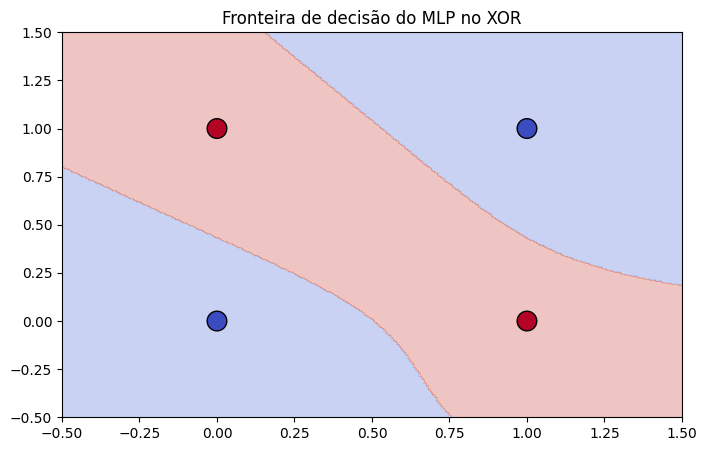

In [20]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

linear = LogisticRegression().fit(X_xor, y_xor)
mlp_xor = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh", solver="lbfgs",
                        max_iter=1000, random_state=1).fit(X_xor, y_xor)

tabela_xor = pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1], "XOR esperado": y_xor,
                           "Regressão Logística": linear.predict(X_xor), "MLP": mlp_xor.predict(X_xor)})
display(tabela_xor)
print(f"Acurácia linear: {linear.score(X_xor, y_xor):.0%} | Acurácia MLP: {mlp_xor.score(X_xor, y_xor):.0%}")

# Fronteira de decisão do MLP
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
Z = mlp_xor.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=200, edgecolor="k")
plt.title("Fronteira de decisão do MLP no XOR"); plt.show()

## Exercício 17: O Impacto Crítico do Escalonamento no MLP
Objetivo: comparar o treinamento da rede neural com e sem `StandardScaler`.

O Breast Cancer tem atributos em escalas muito diferentes (ex.: área ~1000 vs. suavidade ~0,1). Isso prejudica o gradiente descendente.

,Configuração,Acurácia treino,Acurácia teste,Épocas,Loss final
0,Sem StandardScaler,0.9472,0.9415,300,0.1310
1,Com StandardScaler,0.9925,0.9708,300,0.0204


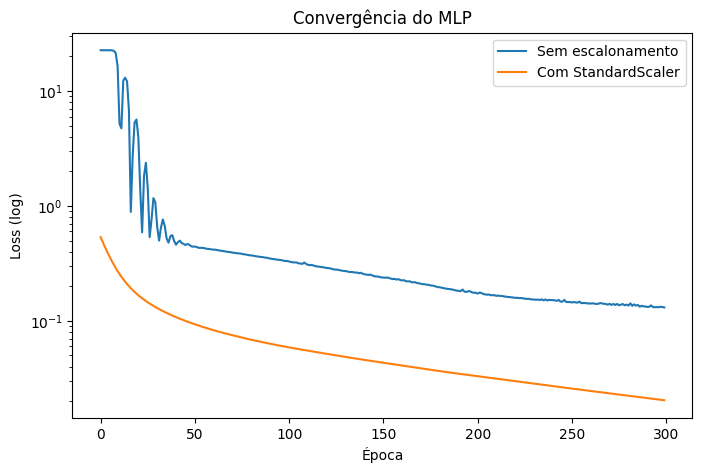

In [21]:
mlp_sem = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=RANDOM_STATE).fit(Xtr_bc, ytr_bc)

scaler_bc = StandardScaler().fit(Xtr_bc)            # fit apenas no treino (evita vazamento de dados)
Xtr_bc_s, Xte_bc_s = scaler_bc.transform(Xtr_bc), scaler_bc.transform(Xte_bc)
mlp_com = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=RANDOM_STATE).fit(Xtr_bc_s, ytr_bc)

display(pd.DataFrame({
    "Configuração": ["Sem StandardScaler", "Com StandardScaler"],
    "Acurácia treino": [mlp_sem.score(Xtr_bc, ytr_bc), mlp_com.score(Xtr_bc_s, ytr_bc)],
    "Acurácia teste": [mlp_sem.score(Xte_bc, yte_bc), mlp_com.score(Xte_bc_s, yte_bc)],
    "Épocas": [mlp_sem.n_iter_, mlp_com.n_iter_],
    "Loss final": [mlp_sem.loss_, mlp_com.loss_],
}).round(4))

plt.plot(mlp_sem.loss_curve_, label="Sem escalonamento")
plt.plot(mlp_com.loss_curve_, label="Com StandardScaler")
plt.yscale("log"); plt.xlabel("Época"); plt.ylabel("Loss (log)"); plt.title("Convergência do MLP")
plt.legend(); plt.show()

## Exercício 18: Análise da Curva de Perda (`loss_curve_`)
Objetivo: visualizar a convergência do erro ao longo das épocas de treino.

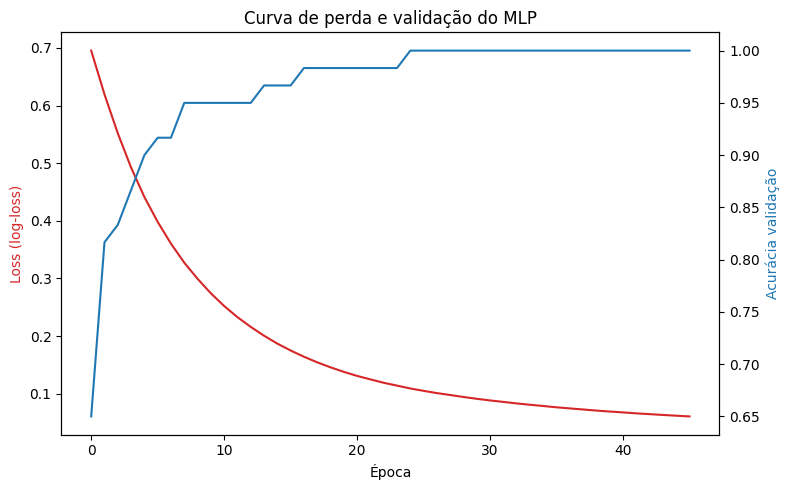

Épocas executadas: 46
Loss inicial: 0.6952 -> loss final: 0.0605
Melhor acurácia de validação: 1.0000
Acurácia no teste: 0.9649


In [22]:
mlp_curva = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True,
                          validation_fraction=0.15, n_iter_no_change=20, random_state=RANDOM_STATE)
mlp_curva.fit(Xtr_bc_s, ytr_bc)

fig, ax1 = plt.subplots()
ax1.plot(mlp_curva.loss_curve_, color="tab:red", label="Loss de treino")
ax1.set_xlabel("Época"); ax1.set_ylabel("Loss (log-loss)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(mlp_curva.validation_scores_, color="tab:blue", label="Acurácia de validação")
ax2.set_ylabel("Acurácia validação", color="tab:blue")
plt.title("Curva de perda e validação do MLP"); fig.tight_layout(); plt.show()

print(f"Épocas executadas: {mlp_curva.n_iter_}")
print(f"Loss inicial: {mlp_curva.loss_curve_[0]:.4f} -> loss final: {mlp_curva.loss_curve_[-1]:.4f}")
print(f"Melhor acurácia de validação: {mlp_curva.best_validation_score_:.4f}")
print(f"Acurácia no teste: {mlp_curva.score(Xte_bc_s, yte_bc):.4f}")

## Exercício 19: Comparativo de Funções de Ativação (`relu`, `logistic`, `tanh`)
Objetivo: avaliar a acurácia no teste alterando a função de ativação das camadas ocultas.

,Ativação,Acurácia teste,Épocas,Tempo (s)
0,relu,0.9708,241,0.3599
1,logistic,0.9649,312,0.5048
2,tanh,0.9649,323,0.5460


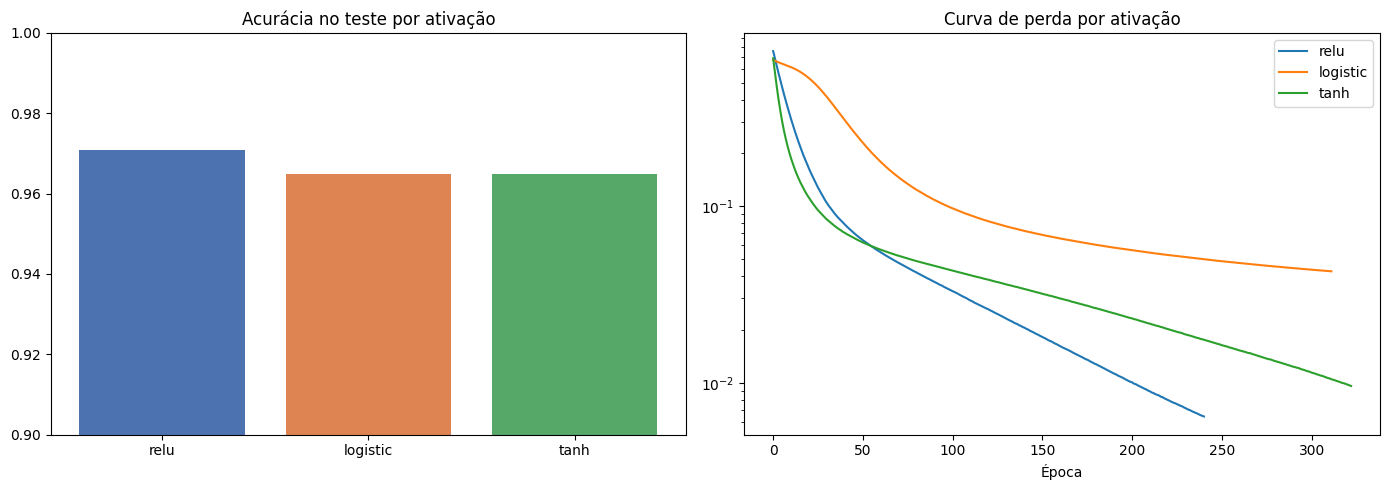

In [23]:
resultados_ativ = []
for ativ in ["relu", "logistic", "tanh"]:
    t0 = time.perf_counter()
    m = MLPClassifier(hidden_layer_sizes=(50, 25), activation=ativ, max_iter=1000, random_state=RANDOM_STATE)
    m.fit(Xtr_bc_s, ytr_bc)
    resultados_ativ.append({"Ativação": ativ, "Acurácia teste": m.score(Xte_bc_s, yte_bc),
                            "Épocas": m.n_iter_, "Tempo (s)": time.perf_counter() - t0,
                            "curva": m.loss_curve_})

df_ativ = pd.DataFrame(resultados_ativ)
display(df_ativ.drop(columns="curva").round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(df_ativ["Ativação"], df_ativ["Acurácia teste"], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_ylim(0.9, 1.0); axes[0].set_title("Acurácia no teste por ativação")
for r in resultados_ativ:
    axes[1].plot(r["curva"], label=r["Ativação"])
axes[1].set_yscale("log"); axes[1].set_xlabel("Época"); axes[1].set_title("Curva de perda por ativação"); axes[1].legend()
plt.tight_layout(); plt.show()

## Exercício 20: Tabela Comparativa de Todos os Modelos Estudados
Objetivo: construir um pipeline completo comparando Regressão Logística, KNN, Árvore de Decisão e MLP em um único script.

Cada modelo roda dentro de um `Pipeline` (StandardScaler + modelo) e é avaliado com validação cruzada estratificada de 5 folds em três datasets.

,Dataset,Modelo,Tipo,Acc treino,Acc teste (CV),Desvio,F1 macro,Tempo fit (s),Tempo pred (s)
0,Breast Cancer,Regressão Logística,Paramétrico,0.988100,0.973700,0.016600,0.971400,0.007600,0.005400
1,Breast Cancer,KNN (k=5),Não paramétrico,0.975800,0.963100,0.017900,0.959900,0.002800,0.006200
2,Breast Cancer,Árvore de Decisão,Não paramétrico,0.992100,0.928000,0.023000,0.921500,0.012500,0.004000
3,Breast Cancer,MLP,Paramétrico,1.000000,0.966700,0.024400,0.964300,0.445000,0.004300
4,Wine,Regressão Logística,Paramétrico,1.000000,0.983300,0.013600,0.982900,0.010700,0.004800
5,Wine,KNN (k=5),Não paramétrico,0.976100,0.971700,0.018100,0.972100,0.002900,0.007000
6,Wine,Árvore de Decisão,Não paramétrico,1.000000,0.898900,0.029000,0.901200,0.004000,0.004400
7,Wine,MLP,Paramétrico,1.000000,0.983300,0.013600,0.982900,0.135300,0.003600
8,Moons (não linear),Regressão Logística,Paramétrico,0.859500,0.859000,0.025200,0.858900,0.004900,0.005500
9,Moons (não linear),KNN (k=5),Não paramétrico,0.956500,0.943000,0.013600,0.943000,0.003100,0.007800


Dataset,Breast Cancer,Moons (não linear),Wine,Média
Modelo,,,,
MLP,0.9667,0.944,0.9833,0.9647
KNN (k=5),0.9631,0.943,0.9717,0.9593
Regressão Logística,0.9737,0.859,0.9833,0.9387
Árvore de Decisão,0.9280,0.932,0.8989,0.9196


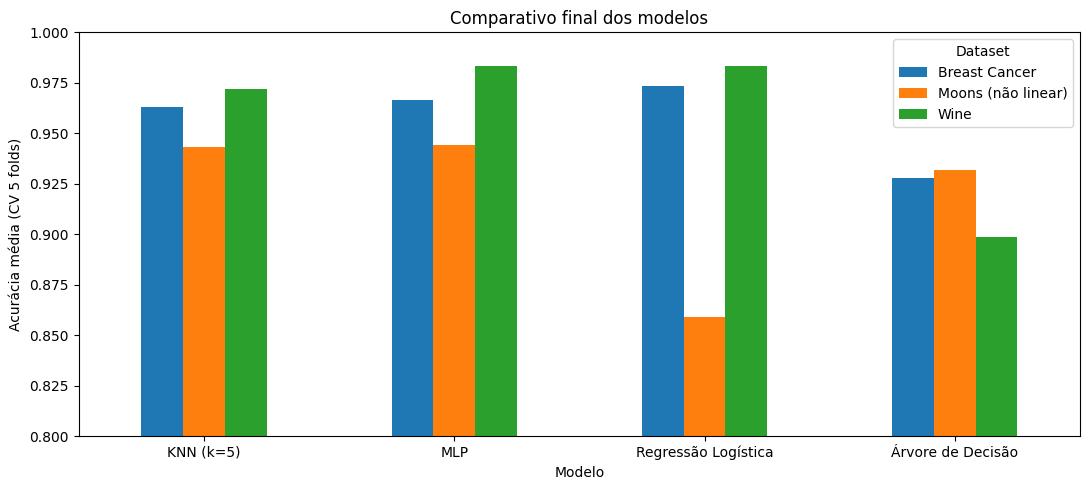

Melhor modelo por dataset:
  Breast Cancer        -> Regressão Logística (0.9737)
  Moons (não linear)   -> MLP (0.9440)
  Wine                 -> Regressão Logística (0.9833)


In [24]:
from sklearn.model_selection import cross_validate, StratifiedKFold

datasets = {
    "Breast Cancer": load_breast_cancer(return_X_y=True),
    "Wine": load_wine(return_X_y=True),
    "Moons (não linear)": make_moons(n_samples=1000, noise=0.25, random_state=RANDOM_STATE),
}
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=2000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "MLP": MLPClassifier(hidden_layer_sizes=(50, 25), max_iter=1000, random_state=RANDOM_STATE),
}
tipo = {"Regressão Logística": "Paramétrico", "KNN (k=5)": "Não paramétrico",
        "Árvore de Decisão": "Não paramétrico", "MLP": "Paramétrico"}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
linhas = []
for nome_ds, (X, y) in datasets.items():
    for nome_m, modelo in modelos.items():
        pipe = make_pipeline(StandardScaler(), modelo)
        r = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True)
        linhas.append({
            "Dataset": nome_ds, "Modelo": nome_m, "Tipo": tipo[nome_m],
            "Acc treino": r["train_accuracy"].mean(),
            "Acc teste (CV)": r["test_accuracy"].mean(),
            "Desvio": r["test_accuracy"].std(),
            "F1 macro": r["test_f1_macro"].mean(),
            "Tempo fit (s)": r["fit_time"].mean(),
            "Tempo pred (s)": r["score_time"].mean(),
        })

resultado = pd.DataFrame(linhas)
display(resultado.round(4).style.highlight_max(subset=["Acc teste (CV)", "F1 macro"], color="lightgreen"))

# Resumo: acurácia média de teste por modelo e dataset
pivot = resultado.pivot(index="Modelo", columns="Dataset", values="Acc teste (CV)")
pivot["Média"] = pivot.mean(axis=1)
display(pivot.sort_values("Média", ascending=False).round(4))

pivot.drop(columns="Média").plot(kind="bar", figsize=(11, 5))
plt.ylim(0.8, 1.0); plt.ylabel("Acurácia média (CV 5 folds)")
plt.title("Comparativo final dos modelos"); plt.xticks(rotation=0); plt.legend(title="Dataset")
plt.tight_layout(); plt.show()

print("Melhor modelo por dataset:")
for ds, grupo in resultado.groupby("Dataset"):
    best = grupo.loc[grupo["Acc teste (CV)"].idxmax()]
    print(f"  {ds:<20} -> {best['Modelo']} ({best['Acc teste (CV)']:.4f})")

## Conclusões

- Paramétricos (Regressão Logística, MLP) têm número fixo de parâmetros e inferência rápida; não paramétricos (KNN, Árvore) se adaptam à forma dos dados, e o KNN guarda o treino inteiro, ficando mais lento para prever.
- Escalonamento é decisivo para modelos baseados em distância (K-Means, KNN) e para redes neurais (MLP).
- Cotovelo e silhueta ajudam a escolher o K; o DBSCAN detecta ruídos e grupos não esféricos onde o K-Means falha.
- Em árvores, `max_depth` (pré-poda) e `ccp_alpha` (pós-poda) controlam o overfitting; `feature_importances_` mostra quais variáveis importam.
- O MLP resolve problemas não lineares como o XOR, e a escolha da ativação e do escalonamento afeta a convergência.